# Citi Bike Demand During G Train Disruptions: data preparation

## DATA 622 Final Project

This notebook is Section 2 of the project. It explains how the data is collected and cleaned by Databricks jobs, which tables those jobs create in the Unity Catalog, where each source comes from, and the checks behind every analysis table. It only reads tables: all downloads and cleaning run in the Databricks jobs.

The research question, exploration, models and evaluation (Sections 1 and 3 to 9) are in [02_citibike_demand_analysis.ipynb](02_citibike_demand_analysis.ipynb), which reads the tables documented here. Run this notebook to review the data, for example after the jobs have added a new month; the analysis notebook does not depend on it.

## Contents

2. Data preparation: collection, understanding, and cleaning
   - Data pipeline in Databricks: jobs, cleaning rules, catalog tables and data access
   - 2.1 to 2.4 Sources, collection, quality checks and integration (including 2.2.1 confirmed G closure windows)
   - 2.5 Exposure definition and analysis panel
   - 2.6 Extended datasets for modeling: shutdown table, extended panel, baseline, status proxy and 2024 check

# 2. Data preparation: collection, understanding, and cleaning

This section explains where the data comes from, how it is collected and cleaned, and which tables the analysis uses. The data work runs in **Databricks**, not in this notebook. Three scheduled Databricks jobs download the raw data, clean it and store the results as tables in the Unity Catalog. The notebook then reads those tables. This keeps the 20 GB of raw trip files out of the notebook, makes every run start from the same cleaned data, and lets new data arrive without anyone rerunning a download.

The rest of this introduction describes the pipeline: the jobs (A), the cleaning rules (B), the tables in the catalog (C) and how the notebook reads them (D). Sections 2.1 to 2.6 then document each source and show the checks and derived tables in detail.

### Overview of the data pipeline

```mermaid
flowchart TB
    subgraph SRC["Public data sources"]
        direction LR
        S1["Citi Bike trip archives<br/>monthly ZIP files on Amazon S3"]
        S2["MTA and NY Open Data APIs<br/>alerts, incidents, stations, ridership"]
        S3["Open-Meteo<br/>hourly weather archive"]
        S4["Citi Bike GBFS<br/>live station feeds"]
        S5["Station status and station<br/>information export"]
    end

    subgraph JOBS["Databricks jobs (serverless)"]
        direction LR
        J1["<b>citibike-download</b><br/>Mondays 06:00<br/>downloads and unzips trip months"]
        J2["<b>external-data-download</b><br/>daily 05:00<br/>MTA, weather and GBFS files"]
        J3["<b>citibike-prepare</b><br/>after each weekly download<br/>cleans files, builds tables"]
    end

    subgraph UC["Unity Catalog: workspace.citibike"]
        V[("<b>Volume raw/datasource</b><br/>raw files, unchanged")]
        subgraph TABLES["Delta tables"]
            direction LR
            T1[("<b>Raw tables</b><br/>raw_* (10)<br/>reference files as tables")]
            T2[("<b>Cleaned tables</b> (7)<br/>trips, trips_station_hourly,<br/>station_status_hourly, stations,<br/>weather_hourly, mta_g_stops")]
            T3[("<b>Analysis tables</b> (11)<br/>station hour panels, station sets,<br/>closures, baselines, quality checks")]
        end
    end

    NB["<b>Project notebooks</b><br/>01 data preparation: Section 2<br/>02 analysis: Sections 1, 3 to 9"]

    S1 --> J1
    S2 --> J2
    S3 --> J2
    S4 --> J2
    S5 -.->|uploaded once| V
    J1 -->|trip CSV files| V
    J2 -->|MTA, weather, GBFS files| V
    J1 ==>|then starts| J3
    V --> J3
    J3 --> T1
    J3 --> T2
    J3 --> T3
    T1 -->|read_table| NB
    T2 -->|read_table| NB
    T3 -->|read_table| NB

    classDef source fill:#eef2f7,stroke:#5b6b82,color:#1f2a37
    classDef job fill:#fdebd3,stroke:#c26a00,color:#3d2200
    classDef storage fill:#e3f1e6,stroke:#2f7d43,color:#123d1e
    classDef consumer fill:#e6e9fb,stroke:#3f4fbf,color:#141c4d
    class S1,S2,S3,S4,S5 source
    class J1,J2,J3 job
    class V,T1,T2,T3 storage
    class NB consumer
```

*Figure 0. Data pipeline.* Grey boxes are the public sources, orange boxes the Databricks jobs, green shapes the storage in the Unity Catalog and blue the two project notebooks. Solid arrows are scheduled data flows, the dotted arrow is the one time upload of the station export, and the thick arrow shows that `citibike-download` starts `citibike-prepare` when it finishes. Both notebooks read the tables with `read_table` (part D below).

The pipeline is defined in the project repository as a Databricks Asset Bundle (`databricks.yml` with one job definition per file in `resources/`). The job notebooks are in `jobs/`, and the code they share with this notebook is in `src/citibike/`. Deploying the bundle creates the jobs in the workspace; the `dev` target keeps the schedules paused for testing and the `prod` target turns them on.

### A. Databricks jobs

All three jobs run on serverless compute (the only option on Databricks Free Edition). Each one takes the catalog, schema and volume as parameters (defaults `workspace`, `citibike`, `raw`), retries automatically on failure, and emails the owner if it fails or runs much longer than usual.

| Job | Notebook | When it runs | What it does | Output |
|---|---|---|---|---|
| `citibike-download` | `jobs/citibike_download.py` | Mondays 06:00 New York time | Downloads each monthly Citi Bike trip archive (May to September 2024 and January 2026 onward) and unzips it into one folder of CSV files per month. Every run also checks the last three months for newly published archives, so new months arrive without code changes. A month that is already complete is skipped, so a run with nothing new takes minutes. When the download finishes, it starts `citibike-prepare`. | `YYYYMM-citibike-tripdata/*.csv` in the volume |
| `external-data-download` | `jobs/external_data_download.py` | Daily 05:00 New York time | Collects every non-trip source: MTA subway alerts for 2026 and monthly G delay incidents (re-downloaded every day), the live MTA alert feed and the Citi Bike GBFS station feeds (a timestamped copy is archived every day, which builds the history the live feeds do not keep), and one-time downloads of the MTA subway stations, the 2012 to 2020 G alerts, hourly ridership at the G stations and the historical weather. Hourly weather for the Greenpoint grid cell is extended every day. Weather is requested in UTC and converted to New York time so that daylight saving time is handled correctly. | MTA, weather and GBFS files in the volume |
| `citibike-prepare` | `jobs/citibike_prepare.py` | After every `citibike-download` run, or started by hand | Cleans the raw files and builds all the Delta tables listed in part C. Trip months are loaded incrementally: a month is read only when it is new or its files changed, and the other tables are rebuilt in a few minutes. It records every quality check in the `data_quality_checks` table. | 34 Delta tables in `workspace.citibike` |

Two inputs are not downloaded by a job: the historical station status snapshots (`station_status/`, an export from a GBFS poller, August 21 to October 1, 2026) and the station information snapshots (`station_info.parquet`). They were uploaded to the volume once. The MTA Weekender closure windows are entered by hand from the MTA notices and kept in `src/citibike/study.py` (Section 2.2.1).

### B. Cleaning rules applied by `citibike-prepare`

The rules below are the same ones described in Section 2.3. The job applies them once to all the data, and records how many rows each rule affected.

| Data | Cleaning and preparation | Where to check the result |
|---|---|---|
| Trips (63.5 million rows read from 15 months of CSV files) | All fields are read as text and then typed. Station codes stay text, so codes such as `4665.02` keep their exact form. Times are parsed as New York clock time. Trips with a missing or unreadable start or end time, or an end time at or before the start, are removed. Repeated `ride_id` values are removed. Trips without a start or end station are kept, because the other end can still be counted. A trip duration in minutes is added. | `trips_ingest_log`: rows read, missing stations, invalid times, nonpositive durations, duplicates and rows kept for each month. In the current data no row failed the time, duration or duplicate rules. |
| Hourly demand | Departures are counted by start station and start hour, and arrivals by end station and end hour. | `trips_station_hourly` |
| Station status (29.6 million snapshots) | Fetch times are converted from UTC to New York time. Snapshots are summarized per station and hour: mean bikes and docks available, minimum open docks, number of snapshots with no bikes or no docks, and number of snapshots. | `station_status_hourly`; checks for missing values and negative counts are in `data_quality_checks` (none found) |
| Stations | The latest daily snapshot is used for location and capacity. The station information field `short_name` links the trip station codes to the GBFS `station_id` used by the status data. | `stations` |
| Weather | The two Open-Meteo files are combined into one hourly series for the Greenpoint grid cell, which serves all 43 Greenpoint stations. | `weather_hourly` |
| MTA files | Values are kept unchanged; only dates are parsed and column names are put in snake case. The G stops are selected from the subway stations file. | `raw_*` tables, `mta_g_stops` |

After cleaning, the job builds the study tables exactly as described in Sections 2.2 to 2.6, with the functions in `src/citibike/transformations.py`. This notebook uses the same functions where it rebuilds small lookups, so the job and the notebook cannot drift apart.

### C. Tables in the catalog

All tables are Delta tables in the schema `workspace.citibike`, next to the volume `raw` that holds the downloaded files. Row counts are as of November 21, 2026; the trip, weather and alert tables grow as the jobs add data, while the analysis panels cover the fixed study periods. The cell after the notebook setup lists the current tables and row counts.

**Raw tables.** One table per reference file, with the values unchanged. They make every source available as a table, including from a local editor.

| Table | Rows | Content |
|---|---:|---|
| `raw_station_info` | 108,047 | Daily station information snapshots (all snapshots of the export) |
| `raw_mta_subway_stations` | 496 | MTA subway stations file (all lines) |
| `raw_mta_subway_alerts_2026` | 30,794 | MTA subway alert updates for 2026 |
| `raw_mta_g_alerts_2012_2020` | 2,640 | Historical alert updates that mention the G train |
| `raw_mta_g_delay_incidents_monthly` | 308 | Monthly G line delay incidents by category |
| `raw_mta_g_station_hourly_ridership_2026` | 36,514 | Hourly ridership at the 21 G station complexes, August to mid October 2026 |
| `raw_mta_live_alerts_snapshot` | 1 | The live MTA alert feed snapshot used in Section 2.1, stored as one JSON document |
| `raw_greenpoint_station_weather_lookup` | 43 | Greenpoint station to weather grid cell lookup |
| `raw_greenpoint_weather_hourly_2026` | 3,336 | Hourly weather for 2026, extended daily |
| `raw_greenpoint_weather_hourly_extended` | 8,016 | Hourly weather for May to September 2024 and February to July 2026 |

**Cleaned tables.** General purpose tables that any analysis can start from.

| Table | Rows | Grain | Content |
|---|---:|---|---|
| `trips` | 63,473,804 | one trip | Cleaned trips with typed times and coordinates, duration and the source month (`trip_month`), May 2024 to October 2026 |
| `trips_ingest_log` | 15 | trip month | Source files, rows read, rows removed by each rule and rows kept |
| `trips_station_hourly` | 15,658,468 | station code by hour | Departures and arrivals for every station and month (hours with at least one trip) |
| `station_status_hourly` | 2,472,520 | station by hour | Hourly availability summary for 2,527 stations, August 21 to October 1, 2026 |
| `stations` | 2,520 | station | Latest station snapshot with location, capacity, distance to the nearest G stop and study group |
| `weather_hourly` | 11,352 | hour | Temperature (degrees Celsius) and precipitation (mm) for the Greenpoint grid cell |
| `mta_g_stops` | 21 | G stop | G train stops with coordinates and the affected segment flag |

**Analysis tables.** The study specific tables built in Sections 2.1 to 2.6 and used in Sections 3 to 6. The job computes every one of them, so the notebook only loads them and never repeats a preparation step.

| Table | Rows | Built in | Used for |
|---|---:|---|---|
| `g_service_closures_confirmed` | 4 | 2.2.1 | The August and September 2026 G closure weekends (220 closure hours) |
| `g_service_closures_confirmed_pre_august` | 9 | 2.2.1 | The earlier 2026 closure weekends |
| `g_service_reduction_windows_inferred` | 8 | 2.1 | Closure windows inferred from G ridership, a check on the notices |
| `greenpoint_station_exposure` | 43 | 2.5 | Distance from each Greenpoint station to the nearest affected stop and its exposure band |
| `analysis_station_hour_panel` | 62,952 | 2.5 | Greenpoint stations by hour, August and September 2026, the only panel with station availability |
| `model_station_sets` | 154 | 2.6 | The 94 corridor and 60 control stations |
| `mta_subway_shutdowns` | 118 | 2.6 | One row per shutdown event and affected G stop (16 events) |
| `analysis_station_hour_panel_extended` | 1,485,072 | 2.6 | **Main modeling table**: 153 stations by hour for May to September 2024 and January to September 2026, with outcomes, weather, calendar, closure flags, baseline, profile, status proxy and the train, validation and test split |
| `baseline_accuracy_by_month` | 24 | 2.6 | Error of the four week baseline, the reference every model must beat |
| `shutdown_effect_screening` | 10 | 2.6 | Actual to normal demand at exposed and control stations for each event type (Figure 10) |
| `trip_hourly_model_stations` | 918,338 | 2.1, 2.6 | Departures and arrivals per model station, trip file month and hour for the 14 study months (the hourly trip counts of Sections 2.1 and 2.6) |
| `greenpoint_station_g_stop_distances` | 903 | 2.1 | Distance from every Greenpoint station to every G stop, with the quarter mile flag |
| `mta_g_service_events` | 24 | 2.1 | G alerts of the live MTA feed snapshot, one row per alert and active period |
| `shutdown_events` | 16 | 2.6 | One row per shutdown event with its window and affected G stops |
| `model_station_g_stop_distances` | 1,848 | 2.6 | Distance from every model station to every G stop (used for the exposure map) |
| `status_proxy_check` | 5 | 2.6 | How well the change in bikes available tracks trip net flow |
| `data_quality_checks` | 40 | all | Every check recorded by the latest `citibike-prepare` run |

Sections 3 to 6 ([02_citibike_demand_analysis.ipynb](02_citibike_demand_analysis.ipynb)) start from `analysis_station_hour_panel_extended` (models and evaluation) and `analysis_station_hour_panel` (station availability). Its Section 3.8 describes the columns of the extended panel and the rules to follow before modeling.

### D. How this notebook reads the data

The setup cell below connects to Databricks and defines one helper, `read_table(name, columns, where)`. The helper sends the query to Databricks, applies any column selection and filter there, and returns only the result as a pandas table. Large aggregations, such as counting hourly trips from the 63 million trip rows, also run in Databricks (`data_access.hourly_station_flows`). As a safeguard, a query that would return more than 3 million rows stops with an error instead of downloading a whole table.

The notebook runs in two places with the same code:

* **In Databricks**, it uses the workspace's own Spark session, and the catalog, schema and volume can be changed with the widgets at the top of the notebook.
* **In VS Code**, Databricks Connect sends the same queries to serverless compute in the workspace, while pandas, the figures and the models run on the local computer. The schema can be changed with the `CITIBIKE_CATALOG`, `CITIBIKE_SCHEMA` and `CITIBIKE_VOLUME` environment variables. Setup steps are in the repository README.

No cell in this notebook downloads, unzips or writes data. If a table is missing, the notebook stops with a "table not found" error; running the `citibike-prepare` job builds it.

## 2.1 Data sources and provenance

The project uses the following data sources. All of them are stored in the Databricks volume and loaded into the tables described above. External sources are requirements for a later event comparison, not data already analyzed.

1. **Citi Bike trip history.** Monthly trip records are stored in monthly archive folders for May to September 2024 and January to September 2026, which the `citibike-download` job downloads and unzips, adding newly published months automatically. The analysis uses trip start time, end time, start station identifier, and end station identifier.
2. **Historical Citi Bike station status.** The local Parquet snapshots were supplied as an NYC export from BigQuery and contain a fetch timestamp, canonical station identifier, reported available bikes, and reported open docks. Snapshot times are recorded in UTC and converted to New York local time for analysis. The file metadata is the provenance record: the snapshots come from a GBFS status poller (poller version 1.2, run manually), were written by a Spark export job on October 1, 2026, and are partitioned by `nyc_date` from August 21 to October 1, 2026. The first usable snapshot hour is August 21, 17:00 New York time.
3. **Citi Bike station information.** Local dated snapshots contain canonical station identifiers, short station identifiers, station names, coordinates, and capacity. The short identifier provides the crosswalk from trip history to station status.
4. **Weather.** Hourly temperature and precipitation are retrieved from the Open Meteo historical archive for May to September 2024 and January to September 2026, which covers all trip months and the full station status window. The station to weather grid mapping follows the method in the Citi Bike data pipeline reference. The project proposal also identifies BigQuery weather as a possible source; this notebook uses the documented API source because no local BigQuery weather table was supplied.
5. **MTA service alerts.** Subway alert updates are retrieved from the New York State Open Data API. The API record date is the notice time, not necessarily the actual service interruption time. The available archive currently ends on August 11, 2026. The live MTA alert feed is also read as a snapshot and parsed into G service event periods with affected stops and start and end times; it only lists work from October 19, 2026 onward, so neither alert source gives closure hours inside the station status period. Closure intervals therefore come from the MTA Weekender planned service notices (Section 2.2.1), which are cross checked against hourly ridership at G stations. Monthly G line delay causing incident counts are collected as context.
6. **MTA subway stops.** G train stop names and coordinates are read from the local MTA Subway Stations file (`MTA_Subway_Stations_20261003.csv`, 496 stops, 21 with G service), exported from New York State Open Data. These coordinates support distance based station exposure after event alerts have been validated.

The monthly trip files, station files, weather, alert and stop data are collected by the `citibike-download` and `external-data-download` Databricks jobs and turned into tables by `citibike-prepare` (see the overview above); this notebook does not download or unzip anything. Historical station status was obtained from BigQuery and uploaded once to `datasource/station_status` in the volume, together with `station_info.parquet`. The related New York BigQuery tables are `bigquery-public-data.new_york_citibike.citibike_stations` and `citibike_trips`; the status files are an NYC export partitioned by `nyc_date`, and the export job metadata is recorded in the data sources document (`docs/data_sources.md`). API URLs, query filters, coverage, units, and limits are recorded in the corresponding code and the data sources document (`docs/data_sources.md`).

### Notebook setup

The next cell makes the project package `src/citibike` importable, reads the catalog, schema and volume settings, opens the Spark session and checks that every trip month used by the study has been loaded. The cell after it lists the tables currently in the catalog.

In [1]:
import sys
from pathlib import Path

# Make src/ importable: walk up from this notebook to the folder that holds databricks.yml.
REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "databricks.yml").exists()), None)
if REPO_ROOT is None:
    raise FileNotFoundError(f"Could not find the project root (databricks.yml) above {Path.cwd()}")
if str(REPO_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(REPO_ROOT / "src"))

import numpy as np
import pandas as pd
from citibike import data_access, study
from citibike import transformations as tf
from citibike.notebook import connect

# Catalog, schema and volume (notebook widgets in Databricks, CITIBIKE_* environment variables or defaults elsewhere),
# the Spark session, and read_table(name, columns, where) to load a project table as pandas
CONFIG, spark, read_table = connect(globals().get("dbutils"))


# Trip file months used in Section 2.1 (January, August and September 2026) and the extra months of Section 2.6
TRIP_MONTHS = tuple(month.replace("-", "") for month in study.TRIP_MONTHS)
TRIP_MONTHS_EXTENDED = tuple(month.replace("-", "") for month in study.EXTENDED_MONTHS if month not in study.TRIP_MONTHS)

ingest_log = read_table("trips_ingest_log").sort_values("trip_month").reset_index(drop=True)
missing_months = sorted(set(study.EXTENDED_MONTHS) - set(ingest_log["trip_month"]))
if missing_months:
    raise LookupError(f"Trip months {missing_months} are not in {CONFIG.catalog}.{CONFIG.schema}.trips. "
                      "Run the citibike-download job (it starts citibike-prepare) first.")
print("Tables:", f"{CONFIG.catalog}.{CONFIG.schema}")
print(f"Trip months ready: {len(study.EXTENDED_MONTHS)}")

c:\Users\simon\OneDrive\Documents\GitHub\data622_nyc_bikes_project\.venv\Lib\site-packages\databricks\sdk\_widgets\__init__.py:70: UserWarning: 
To use databricks widgets interactively in your notebook, please install databricks sdk using:
	pip install 'databricks-sdk[notebook]'
Falling back to default_value_only implementation for databricks widgets.
  warnings.warn(


Tables: workspace.citibike
Trip months ready: 14


In [2]:
# Tables in the project schema with their description and current row count
table_list = spark.sql(f"""
    SELECT table_name, comment
    FROM `{CONFIG.catalog}`.information_schema.tables
    WHERE table_schema = '{CONFIG.schema}'
    ORDER BY table_name
""").toPandas()
table_list.insert(1, "rows", [
    spark.table(f"`{CONFIG.catalog}`.`{CONFIG.schema}`.`{name}`").count() for name in table_list["table_name"]
])
table_list["layer"] = table_list["table_name"].map(
    lambda name: "raw" if name.startswith("raw_") else
    "cleaned" if name in {"trips", "trips_ingest_log", "trips_station_hourly", "station_status_hourly", "stations",
                          "weather_hourly", "mta_g_stops"} else "analysis"
)
print(f"{len(table_list)} tables in {CONFIG.catalog}.{CONFIG.schema}")
display(table_list.sort_values(["layer", "table_name"])[["layer", "table_name", "rows", "comment"]].reset_index(drop=True))

12 tables in workspace.citibike


,layer,table_name,rows,comment
0,cleaned,station_status_hourly,2472520,Bikes and docks available per GBFS station_id ...
1,cleaned,trips,63473804,"Cleaned Citi Bike trips, one row per ride. Tim..."
2,cleaned,trips_ingest_log,15,"Per trip month: source file signature, rows re..."
3,cleaned,trips_station_hourly,15658468,Departures and arrivals per station code (shor...
4,raw,raw_greenpoint_station_weather_lookup,44,Greenpoint station to Open-Meteo grid cell loo...
5,raw,raw_greenpoint_weather_hourly_2026,3336,"Hourly Open-Meteo weather for 2026, extended d..."
6,raw,raw_greenpoint_weather_hourly_extended,8016,Hourly Open-Meteo weather for May to Sep 2024 ...
7,raw,raw_mta_g_alerts_2012_2020,2640,Historical MTA alert updates mentioning the G ...
8,raw,raw_mta_g_delay_incidents_monthly,308,Monthly G line delay incidents by reporting ca...
9,raw,raw_mta_g_station_hourly_ridership_2026,36514,"Hourly ridership at the G station complexes, A..."


In [3]:
# What the jobs have delivered: trip files loaded into the trips table and rows in the station tables
inventory = {
    **{f"{month} trip CSV files loaded": int(ingest_log.loc[ingest_log["trip_month"].eq(month), "csv_files"].sum())
       for month in study.TRIP_MONTHS},
}
for name in ("station_status_hourly", "raw_station_info", "stations", "raw_mta_live_alerts_snapshot"):
    inventory[f"{name} rows"] = spark.table(CONFIG.table(name)).count()
for source, value in inventory.items():
    print(f"{source}: {value}")

AnalysisException: [TABLE_OR_VIEW_NOT_FOUND] The table or view `workspace`.`citibike`.`raw_station_info` cannot be found. Verify the spelling and correctness of the schema and catalog.
Search path: [`system`.`session`, `system`.`builtin`, `system`.`ai`, `workspace`.`default`].
If you did not qualify the name with a schema, verify the current_schema() output, or qualify the name with the correct schema and catalog.
To tolerate the error on drop use DROP VIEW IF EXISTS or DROP TABLE IF EXISTS. SQLSTATE: 42P01;
'Aggregate [unresolvedalias(count(1))]
+- 'UnresolvedRelation [workspace, citibike, raw_station_info], [], false


JVM stacktrace:
org.apache.spark.sql.catalyst.ExtendedAnalysisException
	at org.apache.spark.sql.errors.QueryCompilationErrors$.tableOrViewNotFoundWithSearchPath(QueryCompilationErrors.scala:1710)
	at org.apache.spark.sql.catalyst.analysis.package$AnalysisErrorAt.tableNotFound(package.scala:97)
	at org.apache.spark.sql.catalyst.analysis.RelationResolution$.throwTableNo

**Inventory note:** This cell counts what the Databricks jobs delivered: the trip files loaded into the `trips` table and the rows in the station tables. The next cells load the trip and station data, then the weather and MTA tables. A missing table stops the notebook with a "table not found" error; run the `citibike-prepare` job to build it. Review the source dates and coverage before interpreting the loaded data.

In [ ]:
# Latest station information snapshot with the Greenpoint screen, prepared by citibike-prepare (stations table)
station_info = read_table("stations").sort_values("station_id").reset_index(drop=True)
station_info["station_id"] = station_info["station_id"].astype("string")
station_info["short_name"] = station_info["short_name"].astype("string")
latest_snapshot = station_info["snapshot_date"].max()
greenpoint_stations = station_info[station_info["in_greenpoint_screen"]].copy()
greenpoint_stations["trip_station_id"] = greenpoint_stations["short_name"]
greenpoint_ids = greenpoint_stations["station_id"].dropna().unique()
greenpoint_trip_ids = greenpoint_stations["trip_station_id"].dropna().unique()

# Hourly departures and arrivals at the Greenpoint stations from the January, August and September 2026 trip files
# (table trip_hourly_model_stations, counted per trip file month by citibike-prepare)
code_list = ", ".join(f"'{code}'" for code in greenpoint_trip_ids)
month_list = ", ".join(f"'{month}'" for month in study.TRIP_MONTHS)
trip_demand = (
    read_table("trip_hourly_model_stations", where=f"short_name IN ({code_list}) AND trip_month IN ({month_list})")
    .groupby(["short_name", "hour"], as_index=False)[["departures", "arrivals"]].sum()
    .rename(columns={"short_name": "station_id"})
)
trip_demand["station_id"] = trip_demand["station_id"].astype("string")

# Source checks recorded by the citibike-prepare job for the same trip files
months_log = ingest_log[ingest_log["trip_month"].isin(study.TRIP_MONTHS)]
trip_file_count = int(months_log["csv_files"].sum())
trip_rows = int(months_log["rows_read"].sum())
missing_station_ids = {"departures": int(months_log["missing_start_station"].sum()),
                       "arrivals": int(months_log["missing_end_station"].sum())}
# The job counts a trip with a missing or unreadable start or end time once, for both flows
missing_trip_times = {flow: int(months_log["invalid_time"].sum()) for flow in ("departures", "arrivals")}
invalid_trip_times = {"departures": 0, "arrivals": 0}
invalid_trip_duration_rows = int(months_log["nonpositive_duration"].sum())

# Hourly station status for the Greenpoint stations; the job converted the fetch times from UTC to New York time
id_list = ", ".join(f"'{station_id}'" for station_id in greenpoint_ids)
station_status_hourly = read_table("station_status_hourly", where=f"station_id IN ({id_list})")
station_status_hourly["station_id"] = station_status_hourly["station_id"].astype("string")
station_status_hourly = station_status_hourly.sort_values(["station_id", "hour"]).reset_index(drop=True)
status_source_rows = int(station_status_hourly["snapshot_count"].sum())
job_checks = read_table("data_quality_checks").set_index("check")["result"]
unmatched_trip_station_count = int(job_checks[f"Trip station IDs absent from latest station crosswalk ({', '.join(study.TRIP_MONTHS)})"])
status_missing_values = {"any required field, all stations": int(job_checks["Status snapshots with a missing required value"].replace(",", ""))}
status_negative_count_rows = int(job_checks["Status snapshots with negative bike or dock counts"].replace(",", ""))

print(f"Trip files loaded: {trip_file_count}")
print(f"Trip rows read: {trip_rows:,}")
print(f"Greenpoint station hours with trip records: {len(trip_demand):,}")
print(f"Greenpoint station hours with status records: {len(station_status_hourly):,}")
print(f"Station information records in latest snapshot: {len(station_info):,}")
print(f"Missing station identifiers skipped: {missing_station_ids}")
print(f"Missing trip timestamps skipped: {missing_trip_times}")
print(f"Invalid trip timestamps skipped: {invalid_trip_times}")
print(f"Trips with nonpositive recorded duration excluded: {invalid_trip_duration_rows:,}")
print(f"Greenpoint station status snapshots read: {status_source_rows:,}")
print(f"Status rows with negative bike or dock counts (all stations): {status_negative_count_rows:,}")
print(f"Missing values in required status fields: {status_missing_values}")

Trip files loaded: 13
Trip rows read: 12,045,482
Greenpoint station hours with trip records: 69,170
Greenpoint station hours with status records: 42,243
Station information records in latest snapshot: 2,520
Missing station identifiers skipped: {'departures': 7121, 'arrivals': 38142}
Missing trip timestamps skipped: {'departures': 0, 'arrivals': 0}
Invalid trip timestamps skipped: {'departures': 0, 'arrivals': 0}
Trips with nonpositive recorded duration excluded: 0
Greenpoint station status snapshots read: 505,639
Status rows with negative bike or dock counts (all stations): 0
Missing values in required status fields: {'any required field, all stations': 0}


In [ ]:
import json

mta_subway_alerts = read_table("raw_mta_subway_alerts_2026")
mta_g_stops = read_table("mta_g_stops").sort_values(["stop_name", "gtfs_stop_id"]).reset_index(drop=True)
station_weather_lookup = read_table("raw_greenpoint_station_weather_lookup")
greenpoint_weather = read_table("raw_greenpoint_weather_hourly_2026").sort_values("time").reset_index(drop=True)

print(f"MTA subway alert updates collected: {len(mta_subway_alerts):,}")
print(f"MTA alert update coverage: {mta_subway_alerts['date'].min()} to {mta_subway_alerts['date'].max()}")
print(f"G train stops with coordinates: {len(mta_g_stops):,}")
print(f"Greenpoint stations mapped to weather grid cells: {station_weather_lookup['station_id'].nunique():,}")
print(f"Distinct weather grid cells: {greenpoint_weather['weather_cell_id'].nunique():,}")
print(f"Hourly weather coverage: {greenpoint_weather['time'].min()} to {greenpoint_weather['time'].max()}")
display(greenpoint_weather.groupby("month")[["time", "temperature_2m", "precipitation"]].agg(
    {"time": "count", "temperature_2m": "count", "precipitation": "count"}
).rename(columns={"time": "hourly rows", "temperature_2m": "temperature values", "precipitation": "precipitation values"}))

MTA subway alert updates collected: 30,794
MTA alert update coverage: 2026-01-01 00:05:00 to 2026-08-11 23:51:00
G train stops with coordinates: 21
Greenpoint stations mapped to weather grid cells: 43
Distinct weather grid cells: 1
Hourly weather coverage: 2026-01-01 00:00:00 to 2026-11-16 23:00:00


,hourly rows,temperature values,precipitation values
month,,,
2026-01,744,744,744
2026-08,744,744,744
2026-09,720,720,720
2026-10,744,744,744
2026-11,384,384,384


In [ ]:
# Hourly weather for the extended trip months (2024 shutdown check and 2026 baseline)
extended_weather = read_table("raw_greenpoint_weather_hourly_extended").sort_values("time").reset_index(drop=True)
print(
    f"Extended weather rows: {len(extended_weather):,}; "
    f"missing values: {int(extended_weather[['temperature_2m', 'precipitation']].isna().sum().sum())}"
)

Extended weather rows: 8,016; missing values: 0


In [ ]:
import numpy as np

# Station to G stop distances with the quarter mile flag, and the live MTA alert snapshot parsed into one row per
# G service event and active period. Both are prepared by citibike-prepare (tf.greenpoint_g_stop_distances and
# tf.g_service_events).
stop_pairs = read_table("greenpoint_station_g_stop_distances")
exposed_stop_ids = set(stop_pairs.loc[stop_pairs["within_quarter_mile"], "gtfs_stop_id"])
exposed_station_count = stop_pairs.loc[stop_pairs["within_quarter_mile"], "station_id"].nunique()

g_service_events = read_table("mta_g_service_events").sort_values("start_utc").reset_index(drop=True)
for column in ("start_utc", "end_utc"):
    g_service_events[column] = g_service_events[column].dt.tz_localize("UTC")
feed_time = read_table("raw_mta_live_alerts_snapshot", columns=["feed_timestamp"])["feed_timestamp"].iloc[0].tz_localize("UTC")

# Monthly G line delay causing incidents (open data, covers the status window)
g_delay_incidents = read_table("raw_mta_g_delay_incidents_monthly")

status_window = (pd.Timestamp("2026-08-21", tz="UTC"), pd.Timestamp("2026-10-02", tz="UTC"))
overlap = g_service_events[
    (g_service_events["start_utc"] < status_window[1])
    & (g_service_events["end_utc"].fillna(pd.Timestamp.max.tz_localize("UTC")) > status_window[0])
]
print(f"Greenpoint stations within a quarter mile of a G stop: {exposed_station_count} of {stop_pairs['station_id'].nunique()}")
print(f"Live feed timestamp: {feed_time}")
print(f"G service event periods in live feed: {len(g_service_events):,} ({g_service_events['start_utc'].min()} to {g_service_events['end_utc'].max()})")
print(f"Event periods touching Greenpoint stops: {int(g_service_events['touches_greenpoint_stops'].sum()):,}")
print(f"Event periods overlapping the status window: {len(overlap):,}")
display(g_service_events.groupby("alert_type").size().rename("event periods").to_frame())
display(g_delay_incidents.groupby(g_delay_incidents["month"].dt.to_period("M"))["incidents"].sum().tail(10).rename("G delay incidents").to_frame())

Greenpoint stations within a quarter mile of a G stop: 14 of 43
Live feed timestamp: 2026-11-20 13:49:26+00:00
G service event periods in live feed: 24 (2026-11-24 03:45:00+00:00 to 2026-12-18 20:30:00+00:00)
Event periods touching Greenpoint stops: 3
Event periods overlapping the status window: 0


,event periods
alert_type,
Planned - Part Suspended,9
Planned - Reroute,1
Planned - Stops Skipped,13
Sunday Schedule,1


,G delay incidents
month,
2026-01,181
2026-02,185
2026-03,203
2026-04,212
2026-05,210
2026-06,165
2026-07,191
2026-08,185
2026-09,180


**Historical alert archive.** The MTA Service Alerts 2012 to 2020 dataset uses the agency label Subway and ends on March 31, 2020. It cannot overlap the 2026 station status window, so it is not used to label 2026 hours. It supplies 2,640 G train alert updates (delays, service changes, part suspensions and suspensions) that can be used to test the alert parser, to build a hand checked calendar of past G suspensions, and to plan a comparison with older Citi Bike trip archives. Alert dates are publication times, not confirmed closure times.

In [ ]:
legacy_g_alerts = read_table("raw_mta_g_alerts_2012_2020")

print(f"Legacy G train alert updates (2012 to 2020): {len(legacy_g_alerts):,}")
print(f"Coverage: {legacy_g_alerts['date'].min()} to {legacy_g_alerts['date'].max()}")
display(legacy_g_alerts.groupby("status_label").size().sort_values(ascending=False).head(8).rename("alert updates").to_frame())
display(legacy_g_alerts.groupby(legacy_g_alerts["date"].dt.year).size().rename("alert updates").to_frame())

Legacy G train alert updates (2012 to 2020): 2,640
Coverage: 2012-10-05 07:58:40 to 2020-03-30 04:32:17


,alert updates
status_label,
Delays,1871
Service Change,550
Essential Service,77
Local to Express,65
Part Suspended,16
Multiple Impacts,14
Slow Speeds,9
Some Delays,5


,alert updates
date,
2012,23
2013,113
2014,148
2015,123
2016,334
2017,418
2018,560
2019,681
2020,240


### Ridership check of the G service reduction

No machine readable alert source covers closure hours inside the August 21 to October 1 status window, so ridership serves as an independent check on the planned service notices in Section 2.2.1. The MTA hourly ridership dataset does cover it, and a part suspension of the G through Greenpoint should remove most riders at the two G only stations in the neighborhood, Greenpoint Av and Nassau Av. Hourly ridership for 21 G station complexes is therefore pulled from the MTA hourly ridership dataset and cached. For each station, ridership is divided by the median ridership for the same weekday and clock hour across August 1 to October 14. An hour is flagged when both stations fall below 0.35 of that typical level, the hour is 06:00 or later, and the date is not in the Labor Day holiday period (September 4, 7 and 8). Runs of at least three flagged hours are kept, and runs separated by two hours or less are merged.

Hourly rows for G station complexes: 36,514
Inferred G service reduction windows: 8 (6 inside the station status period)


,start_local,end_local,hours,median_ratio,in_status_window
0,2026-08-08 07:00:00,2026-08-08 22:00:00,15.0,0.00,False
1,2026-08-09 07:00:00,2026-08-10 00:00:00,17.0,0.01,False
2,2026-08-22 06:00:00,2026-08-23 00:00:00,18.0,0.01,True
3,2026-08-23 07:00:00,2026-08-24 00:00:00,17.0,0.01,True
4,2026-09-12 06:00:00,2026-09-12 17:00:00,11.0,0.02,True
5,2026-09-13 10:00:00,2026-09-13 20:00:00,10.0,0.00,True
6,2026-09-26 08:00:00,2026-09-27 00:00:00,16.0,0.01,True
7,2026-09-27 08:00:00,2026-09-27 18:00:00,10.0,0.01,True


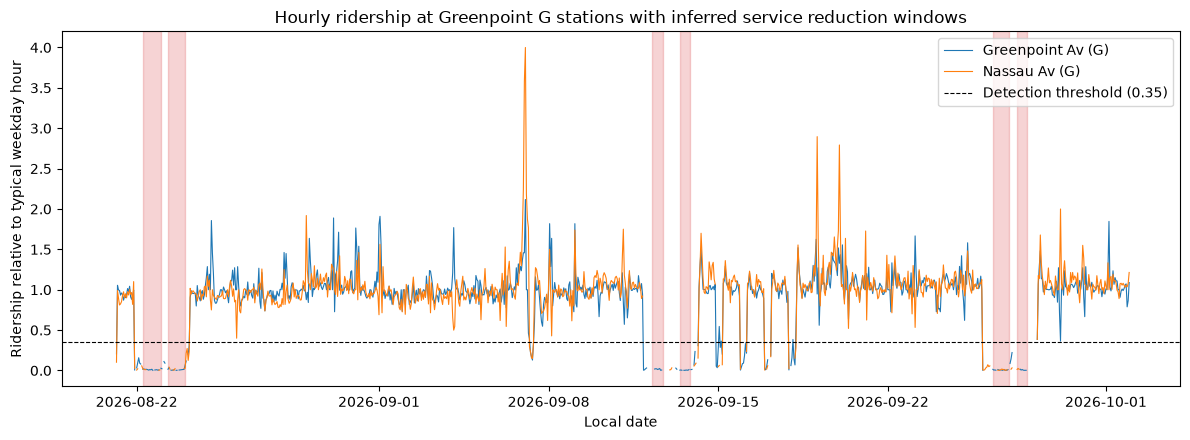

In [ ]:
import matplotlib.pyplot as plt

G_COMPLEX_IDS = study.G_COMPLEX_IDS
g_ridership = read_table("raw_mta_g_station_hourly_ridership_2026")

# Windows where both detector stations keep under 35 percent of their typical ridership for 3+ hours, inferred by
# citibike-prepare (tf.infer_reduction_windows). The ratios are recomputed here only to draw the figure.
g_closure_windows = read_table("g_service_reduction_windows_inferred").sort_values("start_local").reset_index(drop=True)
ridership_wide, ridership_ratio = tf.ridership_ratios(g_ridership)
detector_stations = study.DETECTOR_STATIONS
hour_keys = [ridership_wide.index.dayofweek, ridership_wide.index.hour]

print(f"Hourly rows for G station complexes: {len(g_ridership):,}")
print(f"Inferred G service reduction windows: {len(g_closure_windows)} "
      f"({int(g_closure_windows['in_status_window'].sum())} inside the station status period)")
display(g_closure_windows.assign(median_ratio=g_closure_windows["median_ratio"].round(2)))

fig, ax = plt.subplots(figsize=(12, 4.5))
visible = ridership_ratio.loc["2026-08-21":"2026-10-01 23:00"]
for station in detector_stations:
    ax.plot(visible.index, visible[station], linewidth=0.8, label=station)
for _, window in g_closure_windows[g_closure_windows["in_status_window"]].iterrows():
    ax.axvspan(window["start_local"], window["end_local"], color="tab:red", alpha=0.2)
ax.axhline(0.35, color="black", linestyle="--", linewidth=0.8, label="Detection threshold (0.35)")
ax.set_ylabel("Ridership relative to typical weekday hour")
ax.set_xlabel("Local date")
ax.set_title("Hourly ridership at Greenpoint G stations with inferred service reduction windows")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

**Figure interpretation.** Each line is hourly ridership divided by the typical level for that weekday and hour, so a value of 1 means a normal hour. Both lines stay near 1 on most days and drop close to 0 together during the shaded red windows, which fall on weekends. A common drop at two stations on the same hours is what a service suspension produces, while a station specific issue or a holiday would not move both lines in this way. These windows are inferred from rider counts, not read from an MTA notice, so they are a proxy for closure hours. The start and end times are approximate to the hour, and low ridership caused by weather or a holiday could also be flagged. They should be checked against the MTA planned work notices before they are used as the exposure label.

### 2.2.1 Confirmed G closure windows from MTA planned service notices

The MTA Weekender notices for August 7 to 10, August 21 to 24, September 11 to 14 and September 25 to 28 each state that G trains do not run between Court Sq and Bedford-Nostrand Avs from 9:45 p.m. Friday to 5 a.m. Monday, because of signal modernization, with free shuttle buses between those stations. The weekends of August 14, August 28 and September 18 do not list this work, and the Labor Day weekend notice lists no G work either. These notices replace the ridership inferred windows as the closure definition for the analysis. The ridership windows are kept as an independent check: if the notices are right, the inferred windows should fall inside them. The notices also list stops skipped on the southern F and G section on some weekends, which are not treated as closures here.


The same notices were read for every weekend from January to July 2026 so that the pre August closure weekends can serve as a longer history for the baseline and for placebo checks. Nine of them state the same Court Sq to Bedford-Nostrand Avs suspension: February 27, March 6, March 13, March 20, March 27, April 17, June 5, June 19 and July 10. Together with the four weekends above, that gives 13 confirmed weekends in 2026. The January 2 to 9, 16 and 23 weekends, the February 6, 13 and 20 weekends, April 3, 10 and 24, May 1, 8, 15, 22 and 29, June 12 and 26, and July 3, 17, 24 and 31 weekends do not list it. The February 27 notice states the 9:45 p.m. Friday to 5 a.m. Monday times in full. For the other pre August weekends only the affected segment was read from the notice summary, and the same times are applied, so the `times_assumed` column marks them.

In [ ]:
# MTA Weekender notices (src/citibike/study.py): no G trains between Court Sq and Bedford-Nostrand Avs from
# 9:45 p.m. Friday to 5 a.m. Monday. The citibike-prepare job turns them into g_service_closures_confirmed.
MTA_WEEKENDER_NOTICES = study.MTA_WEEKENDER_NOTICES
g_confirmed_windows = read_table("g_service_closures_confirmed").sort_values("start_local").reset_index(drop=True)

# Whole clock hours fully inside a window: 22:00 Friday through 04:00 Monday
closure_hours = tf.closure_hour_index(g_confirmed_windows)

inferred_hours = pd.DatetimeIndex(np.concatenate([
    pd.date_range(row.start_local, row.end_local - pd.Timedelta(hours=1), freq="h").to_numpy()
    for row in g_closure_windows.itertuples()
]))
agreement = inferred_hours.isin(closure_hours).mean()
print(f"Confirmed closure hours: {len(closure_hours):,} across {len(g_confirmed_windows)} weekends")
print(f"Share of ridership inferred hours that fall inside a confirmed window: {agreement:.1%}")
print(f"Confirmed weekends with at least one inferred window: "
      f"{sum(any((w.start_local <= i_start < w.end_local) for i_start in g_closure_windows['start_local']) for w in g_confirmed_windows.itertuples())} of {len(g_confirmed_windows)}")
display(g_confirmed_windows.drop(columns="notice_url"))

Confirmed closure hours: 220 across 4 weekends
Share of ridership inferred hours that fall inside a confirmed window: 100.0%
Confirmed weekends with at least one inferred window: 4 of 4


C:\Users\simon\AppData\Local\Temp\ipykernel_50288\1830094370.py:10: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  pd.date_range(row.start_local, row.end_local - pd.Timedelta(hours=1), freq="h").to_numpy()


,start_local,end_local,closure_hours
0,2026-08-07 21:45:00,2026-08-10 05:00:00,55
1,2026-08-21 21:45:00,2026-08-24 05:00:00,55
2,2026-09-11 21:45:00,2026-09-14 05:00:00,55
3,2026-09-25 21:45:00,2026-09-28 05:00:00,55


In [ ]:
# The nine earlier 2026 closure weekends (src/citibike/study.py); times_assumed marks notices whose times were inferred
PRE_AUGUST_NOTICES = study.PRE_AUGUST_NOTICES
g_confirmed_pre_august = read_table("g_service_closures_confirmed_pre_august").sort_values("start_local").reset_index(drop=True)
print(f"Confirmed G closure weekends before August 2026: {len(g_confirmed_pre_august)}")
print(f"Confirmed G closure weekends in 2026 in total: {len(g_confirmed_pre_august) + len(g_confirmed_windows)}")

Confirmed G closure weekends before August 2026: 9
Confirmed G closure weekends in 2026 in total: 13


**Interpretation of the closure check.** The four notices define 220 closure hours (55 per weekend, from 22:00 Friday to 04:00 Monday). Every one of the ridership inferred hours falls inside a confirmed window, and each confirmed weekend contains at least one inferred window. Two independent sources therefore agree on when G service was cut. The confirmed windows are longer because the ridership rule only flags daytime hours from 06:00 and needs both Greenpoint Av and Nassau Av to be far below normal, while overnight ridership is too small to separate from usual quiet hours. The confirmed windows are used as the closure indicator in the panel. The August 7 to 10 weekend lies before the station status period, so it supports trip and weather analysis but has no availability data.

**Loaded data:** The code loads hourly departure and arrival counts for the January, August and September trip files, counted in Databricks from the cleaned `trips` table. It also loads the latest station information snapshot and the hourly station status summary built by the `citibike-prepare` job. Trip timestamps are kept in local time; status timestamps were converted from UTC to New York time before aggregation. The hourly tables remain separate so differences in their time coverage are visible before they are joined. Station attributes come from the latest snapshot and may differ from historical station locations or capacity.

In [ ]:
import pandas as pd

GREENPOINT_LATITUDE = (40.720, 40.740)
GREENPOINT_LONGITUDE = (-73.965, -73.935)

greenpoint_stations = station_info.loc[
    station_info["lat"].between(*GREENPOINT_LATITUDE)
    & station_info["lon"].between(*GREENPOINT_LONGITUDE)
    & station_info["capacity"].gt(0)
].copy()
greenpoint_stations["trip_station_id"] = greenpoint_stations["short_name"].astype("string")
greenpoint_ids = greenpoint_stations["station_id"].dropna().unique()
greenpoint_trip_ids = greenpoint_stations["trip_station_id"].dropna().unique()

greenpoint_trips = trip_demand.rename(
    columns={"station_id": "trip_station_id"}
).loc[lambda frame: frame["trip_station_id"].isin(greenpoint_trip_ids)].merge(
    greenpoint_stations[["station_id", "trip_station_id", "name", "lat", "lon", "capacity"]],
    on="trip_station_id",
    how="left",
    validate="many_to_one",
)
greenpoint_trips["date"] = greenpoint_trips["hour"].dt.normalize()
greenpoint_trips["hour_of_day"] = greenpoint_trips["hour"].dt.hour
greenpoint_trips["weekday"] = greenpoint_trips["hour"].dt.day_name()
greenpoint_trips["day_type"] = greenpoint_trips["hour"].dt.dayofweek.map(
    lambda day: "Weekend" if day >= 5 else "Weekday"
)
greenpoint_trips["month"] = greenpoint_trips["hour"].dt.strftime("%Y-%m")

# Hourly status of the Greenpoint stations with station attributes and weekday labels
greenpoint_status = tf.greenpoint_status_frame(station_status_hourly, greenpoint_stations)

trip_hours_by_month = (
    trip_demand.assign(month=trip_demand["hour"].dt.strftime("%Y-%m"))
    .groupby("month")[["departures", "arrivals"]]
    .sum()
)
trip_date_min = trip_demand["hour"].min()
trip_date_max = trip_demand["hour"].max()
status_date_min = station_status_hourly["hour"].min()
status_date_max = station_status_hourly["hour"].max()
current_trip_station_ids = set(station_info["short_name"].dropna())
duplicate_trip_hour_keys = int(trip_demand.duplicated(["station_id", "hour"]).sum())
duplicate_status_hour_keys = int(station_status_hourly.duplicated(["station_id", "hour"]).sum())
duplicate_current_station_ids = int(station_info["station_id"].duplicated().sum())
trip_status_join = greenpoint_trips.merge(
    greenpoint_status[
        ["station_id", "hour", "bikes_available_mean", "docks_available_mean",
         "zero_bike_snapshots", "zero_dock_snapshots", "snapshot_count"]
    ],
    on=["station_id", "hour"],
    how="outer",
    indicator=True,
    validate="one_to_one",
)

quality_summary = pd.DataFrame(
    [
        ("Trip CSV files read", trip_file_count),
        ("Raw trip rows read", trip_rows),
        ("Departure records without a station ID", missing_station_ids["departures"]),
        ("Arrival records without a station ID", missing_station_ids["arrivals"]),
        ("Departure timestamps missing or invalid", missing_trip_times["departures"] + invalid_trip_times["departures"]),
        ("Arrival timestamps missing or invalid", missing_trip_times["arrivals"] + invalid_trip_times["arrivals"]),
        ("Trips with nonpositive recorded duration excluded", invalid_trip_duration_rows),
        ("Greenpoint station status snapshots read", status_source_rows),
        ("Missing values in required status fields", sum(status_missing_values.values())),
        ("Status rows with negative bike or dock counts", status_negative_count_rows),
        ("Latest station information snapshot", str(latest_snapshot)),
        ("Duplicate station IDs in latest station snapshot", duplicate_current_station_ids),
        ("Duplicate trip station hour keys", duplicate_trip_hour_keys),
        ("Duplicate status station hour keys", duplicate_status_hour_keys),
        ("Stations in Greenpoint screening rectangle", len(greenpoint_stations)),
        ("Trip station IDs absent from latest station short name crosswalk", unmatched_trip_station_count),
        ("Greenpoint trip station hours within status date range", int(greenpoint_trips["hour"].between(status_date_min, status_date_max).sum())),
    ],
    columns=["Check", "Result"],
)

print(f"Greenpoint trip time coverage: {trip_date_min} to {trip_date_max}")
print(f"Greenpoint status time coverage: {status_date_min} to {status_date_max}")
print(f"Greenpoint station screen: {len(greenpoint_stations)} stations")
print(f"Greenpoint trip station hours: {len(greenpoint_trips):,}")
print(f"Greenpoint status station hours: {len(greenpoint_status):,}")
print("\nData quality summary")
display(quality_summary)
print("\nTrip activity by calendar month")
display(trip_hours_by_month)
print("\nGreenpoint trip and status key coverage")
display(trip_status_join["_merge"].value_counts().rename_axis("source coverage").to_frame("station hours"))

Greenpoint trip time coverage: 2025-12-31 17:00:00 to 2026-09-30 23:00:00
Greenpoint status time coverage: 2026-08-21 17:00:00 to 2026-10-01 16:00:00
Greenpoint station screen: 43 stations
Greenpoint trip station hours: 69,170
Greenpoint status station hours: 42,243

Data quality summary


,Check,Result
0,Trip CSV files read,13
1,Raw trip rows read,12045482
2,Departure records without a station ID,7121
3,Arrival records without a station ID,38142
4,Departure timestamps missing or invalid,0
5,Arrival timestamps missing or invalid,0
6,Trips with nonpositive recorded duration excluded,0
7,Greenpoint station status snapshots read,505639
8,Missing values in required status fields,0
9,Status rows with negative bike or dock counts,0



Trip activity by calendar month


,departures,arrivals
month,,
2025-12,5,0
2026-01,51585,51478
2026-07,48,0
2026-08,163315,163050
2026-09,151054,151884



Greenpoint trip and status key coverage


,station hours
source coverage,
left_only,35295
both,33875
right_only,8368


**Data preparation results:** The table above records the current file and quality checks. Records without a station identifier cannot be assigned to a station, so they are excluded from station level counts and reported separately. The spatial screen uses a rectangle and current station information; it is suitable for initial description, not for deciding whether a station was affected by a particular closure. The join coverage table compares trip and status station hours. A missing side of the join means that the source has no matching record for that key; it is not a zero count.

The August and September trip records overlap the station status records from August 21. Weather observations, MTA subway alert updates, and G train stop coordinates are collected from the APIs described in Section 2.2. The alert archive ends on August 11, 2026, while historical station status begins on August 21, 2026. Therefore, alert history does not identify G train closure intervals during the station status period. Those intervals come from the MTA Weekender notices in Section 2.2.1 and are checked against ridership. The figures below describe routine patterns and station inventory; they do not estimate the effect of a subway closure.

## 2.2 Collection and data understanding

The `citibike-download` job stores the trip archives in the Databricks volume and extracts them into month folders; the `citibike-prepare` job loads the extracted CSV files into the cleaned `trips` table, which this notebook reads. Historical station status is stored in date partitioned Parquet files. Station information is stored as dated snapshots. The current GBFS JSON files describe their fetch time and are not a substitute for historical status. The `external-data-download` job retrieves hourly Open Meteo archive weather, MTA subway alert updates, and MTA G train stop coordinates into the volume, and each file is available as a `raw_` table.

The trip loader reads every field of the CSV files in Spark and the hourly counts use four of them. Trip records use short station identifiers, while station status uses canonical GBFS identifiers. The station information field `short_name` provides the crosswalk. Trip times are treated as New York local time because the source values have no explicit time zone. Status fetch times are converted from UTC to New York local time. The weather request uses each screened station's coordinates with land cell selection, records the grid coordinates returned by Open Meteo, and reduces repeated station results to unique weather cell and hour records. This follows the station to grid mapping approach in the cited Citi Bike pipeline; its HRRR forecast configuration is not used for historical observations. The resulting station lookup allows each station to be associated with its grid cell. The original source files are left unchanged, and the hourly trip aggregation does not retain individual trip identifiers.

| Source fields | Meaning in the analysis |
| --- | --- |
| `started_at`, `ended_at` | Recorded trip start and end times. |
| `start_station_id`, `end_station_id` | Short identifiers used to assign departures and arrivals. |
| `station_id`, `short_name` | Canonical GBFS key and trip history crosswalk. |
| `name`, `lat`, `lon`, `capacity` | Station description and latest available location and capacity. |
| `fetched_at`, `num_bikes_available`, `num_docks_available` | Status snapshot time, reported bikes, and reported open docks. |
| `temperature_2m`, `precipitation` | Hourly weather at the mapped Open Meteo grid cell; temperature is degrees Celsius and precipitation is millimeters. |
| MTA `date`, `affected`, `header` | Alert update publication time and text fields; they require validation before defining event start or end times. |
| MTA stop coordinates | GTFS stop identifiers and coordinates used to calculate distance to G train stops. |
| Derived station and hour fields | Departure and arrival counts, mean inventory, zero inventory snapshot counts, and snapshot count. |

## 2.3 Data quality checks, results, and cleaning

The loader applies the following checks and transformations:

1. Read four required trip fields in chunks and keep station identifiers as strings so that identifiers with punctuation or leading zeros are preserved. Use the short name crosswalk to focus trip records on the 43 stations in the Greenpoint screening rectangle before parsing their timestamps.
2. Count rows missing a departure or arrival station identifier, then exclude those endpoint rows from station level aggregation. Missing timestamps and timestamps that cannot be parsed are counted separately.
3. Floor valid trip timestamps to the hour. The source timestamps have no explicit offset; the analysis treats the published clock time as New York local time. The convention was checked only for the loaded months. Daylight saving transition dates (March and November) fall in the modeled months and are assumed to be rare enough to ignore here, so they should be reviewed before modeling.
4. Convert the status fetch timestamps from UTC to New York local time. Retain hourly means, the minimum reported open docks, and the number of source snapshots used in each hourly summary.
5. Use the latest station information snapshot for the initial geographic screen. Historical station capacity and location may differ, so event analysis should use station attributes valid at the event date when available.
6. Exclude trips with both timestamps present when the end time is not later than the start time. Match trip station identifiers to the GBFS station identifier through the station information short name field. Match station status directly by GBFS station identifier rather than station name, and report trip identifiers absent from the crosswalk.

### Results of the checks

The checks were run on the seven local trip CSV files, historical status data, and external sources retrieved on October 24, 2026. The table reports measured outcomes and how each was handled.

| Check | Result | Cleaning decision or interpretation |
| --- | --- | --- |
| Trip records read | 6,799,246 | Read in chunks; station level measures were retained for stations in the Greenpoint screen. |
| Departure records without a start station ID | 4,251 | Cannot be assigned to a station; excluded from station level departures and counted in this quality report. |
| Arrival records without an end station ID | 23,375 | Cannot be assigned to a station; excluded from station level arrivals and counted in this quality report. |
| Missing or invalid trip timestamps | 0 | No timestamp rows were excluded for this reason. |
| Trips with end time at or before start time | 0 | No trips were excluded by the duration check. |
| Distinct trip station IDs absent from the latest station crosswalk | 117 | These IDs could not be matched to the latest station list. They are reported for review rather than matched by station name. |
| Screened station status snapshots with missing required values | 0 | No rows were excluded for missing station ID, fetch time, bike count, or dock count. |
| Screened station status snapshots with negative bike or dock counts | 0 | No count corrections or exclusions were required. |
| Duplicate station IDs in the latest station snapshot | 0 | The station information merge did not duplicate station records. |
| Duplicate station by hour keys after aggregation | 0 | Trip and status hourly tables each had unique station and hour keys. |
| MTA subway alert updates retrieved for 2026 | 30,794; latest update August 11 | These are notice updates, not verified service intervals. The archive ends before the station status sample begins. |
| G train stop records retrieved | 21 | Stop coordinates are available for later distance calculations; an alert must first identify which stops lost service. |
| Greenpoint stations linked to weather cells | 43 stations, 1 unique grid cell | The local screen maps all 43 stations to the same returned weather cell. This limits station level weather variation. |
| Hourly weather records | 2,208 for January, August and September combined | Temperature and precipitation are available for the 92 calendar days requested, in New York local time. |

These results support the hourly aggregation for the checks listed, but they do not establish that all source records are error free. The MTA alert date is the notice publication time, not necessarily the disruption start time, and this historical alert feed has no records overlapping the station status sample. This first pass does not assess duplicate ride identifiers, unusually long but positive trip durations, every source quality flag, or whether each station was active throughout the study period. Those checks require additional raw fields or dated station history and should be completed before modeling. Missing trip counts are not changed to zero; zeros are introduced only on the complete calendar grid used for monthly demand plots.

## 2.4 Integration and derived analysis table

Trip records are grouped by start station and start hour for departures, and by end station and end hour for arrivals. The two measures are aligned on station and hour. Status reports are summarized separately at the same grain. The resulting station hour tables can be joined only after their key uniqueness and coverage are checked. Station information adds current location and capacity for an initial screen. Weather values can be joined by local hour and the station to weather cell lookup, after checking coverage. MTA alert updates are collected, but their text must be converted into validated event intervals before they can be used as a disruption indicator. Stop coordinates support a stated distance rule once affected stops and event intervals are known.

A join will be checked for unintended row multiplication, unmatched station identifiers, and timestamps outside source coverage. The alert's publication time will not be treated as the disruption start time unless the source confirms that interpretation. Any method used to extract service times from alert text will be validated against known events.

## 2.5 Disruption exposure and analysis ready dataset

The confirmed closure windows describe when service was reduced, but the model also needs to know which stations are exposed. Two steps turn the windows into model inputs. First, the affected segment is taken from the MTA notices: no G trains run between Court Sq and Bedford-Nostrand Avs, which covers eight G stops (Court Sq, 21 St, Greenpoint Av, Nassau Av, Metropolitan Av, Broadway, Flushing Av and Myrtle-Willoughby Avs). The segment is checked against hourly ridership: a G station complex is flagged by ridership when its median ridership inside the closure windows falls below 35 percent of its typical level for that weekday and hour. Second, each Greenpoint station is assigned the distance in miles to its nearest affected stop, and a station is exposed when that distance is at most a quarter mile, which is the exposure rule in the project proposal.

In [ ]:
segment_complexes = g_ridership[["station_complex_id", "station_complex"]].drop_duplicates().copy()
segment_complexes["station_complex_id"] = segment_complexes["station_complex_id"].astype(str)

typical_ridership = ridership_wide.groupby(hour_keys).transform("median").replace(0, np.nan)
all_ratio = ridership_wide / typical_ridership
in_window_ratio = all_ratio.loc[all_ratio.index.isin(closure_hours)].median()
outside_ratio = all_ratio.loc[~all_ratio.index.isin(closure_hours)].median()
segment_table = segment_complexes.merge(
    pd.DataFrame({
        "station_complex": in_window_ratio.index,
        "ratio_inside_windows": in_window_ratio.to_numpy(),
        "ratio_outside_windows": outside_ratio.to_numpy(),
    }),
    on="station_complex",
)
segment_table["affected"] = segment_table["ratio_inside_windows"] < 0.35
segment_table = segment_table.sort_values("ratio_inside_windows").reset_index(drop=True)
affected_complex_ids = set(segment_table.loc[segment_table["affected"], "station_complex_id"])

# The MTA notices name the segment: no G trains between Court Sq (G22) and Bedford-Nostrand Avs (G33).
# citibike-prepare marks those stops with the affected_segment column of mta_g_stops.
segment_stop_ids = mta_g_stops.loc[mta_g_stops["affected_segment"], "gtfs_stop_id"].sort_values()
notice_complex_ids = set(
    mta_g_stops.loc[mta_g_stops["gtfs_stop_id"].isin(segment_stop_ids), "complex_id"].astype(str)
)
segment_table["named_in_notice"] = segment_table["station_complex_id"].isin(notice_complex_ids)
affected_stops = mta_g_stops[mta_g_stops["gtfs_stop_id"].isin(segment_stop_ids)].copy()

# Nearest affected stop, quarter mile exposure flag and distance band per Greenpoint station (built by citibike-prepare)
station_exposure = read_table("greenpoint_station_exposure").sort_values("station_id").reset_index(drop=True)
station_exposure["distance_band"] = tf.as_distance_band(station_exposure["distance_band"])

print(f"Confirmed closure hours: {len(closure_hours):,}")
print(f"G complexes with a ridership collapse inside the confirmed windows: {len(affected_complex_ids)} of {len(segment_table)}\nG complexes named in the notices: {len(notice_complex_ids)}; ridership flagged complexes also named in the notices: {len(affected_complex_ids & notice_complex_ids)} of {len(affected_complex_ids)}")
display(segment_table.assign(
    ratio_inside_windows=segment_table["ratio_inside_windows"].round(3),
    ratio_outside_windows=segment_table["ratio_outside_windows"].round(3),
))
print("Affected segment stops: " + ", ".join(affected_stops.sort_values("gtfs_stop_id")["stop_name"]))
print(f"Stations within 0.25 mile of an affected stop: {int(station_exposure['exposed_station'].sum())} of {len(station_exposure)}")
display(station_exposure["distance_band"].value_counts().sort_index().rename("stations").to_frame())

Confirmed closure hours: 220
G complexes with a ridership collapse inside the confirmed windows: 6 of 21
G complexes named in the notices: 8; ridership flagged complexes also named in the notices: 6 of 6


,station_complex_id,station_complex,ratio_inside_windows,ratio_outside_windows,affected,named_in_notice
0,283,Greenpoint Av (G),0.010,1.001,True,True
1,284,Nassau Av (G),0.013,1.000,True,True
2,286,Broadway (G),0.017,1.000,True,True
3,288,Myrtle-Willoughby Avs (G),0.018,1.000,True,True
4,282,21 St (G),0.024,1.000,True,True
5,287,Flushing Av (G),0.048,1.000,True,True
6,291,Clinton-Washington Avs (G),0.810,1.000,False,False
7,292,Fulton St (G),0.813,1.009,False,False
8,290,Classon Av (G),0.856,1.000,False,False
9,629,"Metropolitan Av/Lorimer St (G,L)",0.861,1.000,False,True


Affected segment stops: Court Sq, 21 St, Greenpoint Av, Nassau Av, Metropolitan Av, Broadway, Flushing Av, Myrtle-Willoughby Avs
Stations within 0.25 mile of an affected stop: 14 of 43


,stations
distance_band,
Within 0.25 mile,14
0.25 to 0.5 mile,21
Beyond 0.5 mile,8


**Interpretation of the exposure definition.** Six of the 21 G complexes (Greenpoint Av, Nassau Av, Broadway, Myrtle-Willoughby Avs, 21 St and Flushing Av) keep only 1 to 5 percent of their usual entries inside the confirmed windows, while the two transfer complexes stay near normal. All six are also named in the MTA notices, so the ridership check agrees with the notices. The notices name eight stops. The two extra stops, Court Sq and Metropolitan Av, are transfer complexes (ratios 1.09 and 0.86) whose ridership is carried by other lines, so ridership alone cannot flag them. The notice based segment is used for exposure. Of the 43 Citi Bike stations, 14 lie within 0.25 mile of an affected stop, 21 between 0.25 and 0.5 mile, and 8 beyond 0.5 mile. The 14 stations form the exposed group. A limit is that distance to a stop is a proxy for being served by that stop, and riders may walk farther than a quarter mile.

### Station hour panel

The analysis table has one row per station and clock hour from August 1 to September 30, 2026. Trip counts are observed for the whole period, so a station hour with no recorded trip is a true zero. Station status begins on August 21, so earlier rows keep missing availability values instead of zeros, and the `status_observed` flag marks the rows that have them. Weather is joined by hour, exposure and closure flags are added, and calendar and lag features are created. The table is checked for duplicate keys and the expected row count, then saved as the `analysis_station_hour_panel` table by the `citibike-prepare` job; the cell below loads it and repeats the checks.

In [ ]:
PANEL_START, PANEL_END, TRIP_COVERAGE_START = study.PANEL_START, study.PANEL_END, study.TRIP_COVERAGE_START
panel_hours = pd.date_range(PANEL_START, PANEL_END, freq="h")

# Built by tf.greenpoint_panel in the citibike-prepare job
panel = read_table("analysis_station_hour_panel").sort_values(["station_id", "hour"]).reset_index(drop=True)
panel["distance_band"] = tf.as_distance_band(panel["distance_band"])

if panel.duplicated(["station_id", "hour"]).any():
    raise ValueError("The analysis panel contains duplicate station hour keys.")
expected_rows = len(station_exposure) * len(panel_hours)
if len(panel) != expected_rows:
    raise ValueError(f"Panel has {len(panel):,} rows, expected {expected_rows:,}.")

panel_checks = pd.DataFrame([
    ("Stations", panel["station_id"].nunique()),
    ("Hours", len(panel_hours)),
    ("Station hour rows", len(panel)),
    ("Rows with observed trip counts (August and September)", int(panel["trip_observed"].sum())),
    ("Rows with status snapshots", int(panel["status_observed"].sum())),
    ("Rows missing weather", int(panel["temperature_2m"].isna().sum())),
    ("Closure hours (all stations)", int(panel["g_closure_hour"].sum())),
    ("Closure station hours at exposed stations", int(panel["exposed_closure_hour"].sum())),
    ("Closure station hours with observed trips", int((panel["g_closure_hour"] & panel["trip_observed"]).sum())),
], columns=["Check", "Result"])
missing_by_column = panel.isna().sum().loc[lambda counts: counts.gt(0)].rename("missing values").to_frame()
missing_by_column["share"] = (missing_by_column["missing values"] / len(panel)).round(3)

print(f"Analysis panel loaded: {panel.shape[0]:,} rows and {panel.shape[1]} columns")
display(panel_checks)
display(missing_by_column)

Analysis panel loaded: 62,952 rows and 35 columns


,Check,Result
0,Stations,43
1,Hours,1464
2,Station hour rows,62952
3,Rows with observed trip counts (August and Sep...,62952
4,Rows with status snapshots,41512
5,Rows missing weather,0
6,Closure hours (all stations),9460
7,Closure station hours at exposed stations,3080
8,Closure station hours with observed trips,9460


,missing values,share
bikes_available_mean,21440,0.341
docks_available_mean,21440,0.341
zero_bike_snapshots,21440,0.341
zero_dock_snapshots,21440,0.341
snapshot_count,21440,0.341
zero_dock_share,21440,0.341
zero_bike_share,21440,0.341
departures_lag_24h,1032,0.016
departures_lag_168h,7224,0.115


**Interpretation of the analysis panel.** The panel has one row per station and hour: 43 stations over 1,464 hours gives 62,952 rows, and every row has observed trip counts and weather. Status snapshots exist for 41,512 rows (66 percent). The 21,440 rows without status are all hours before August 21 and share the same missingness pattern, so availability features can only be modeled on the later period. The lag features lose 1,032 rows (24 hour lag) and 7,224 rows (168 hour lag) at the start of the series. The 220 confirmed closure hours give 9,460 closure station hours, of which 3,080 are at the 14 exposed stations. This panel rests on four closure weekends, and the extended panel in Section 2.6 widens that to 13.

## 2.6 Extended datasets for modeling

The analysis panel in Section 2.5 covers only the Greenpoint stations in August and September 2026. The project proposal needs more than that: a shutdown table, demand for corridor and control stations, a baseline built from recent normal weeks, a demand proxy from station status, and a 2024 shutdown check. The `citibike-prepare` job builds those tables from the trip months listed in Section 2.1 and saves each one as a Delta table; the cells below load them.

| Table | Variable | Delta table | Purpose |
|---|---|---|---|
| Shutdown table | `mta_subway_shutdowns` | `mta_subway_shutdowns` | One row per shutdown event and affected G stop, with the Citi Bike stations within 0.25 mile |
| Station sets | `model_stations` | `model_station_sets` | Corridor stations and a random sample of control stations |
| Hourly trips | `trip_hourly` | `trips` (counted on load) | Departures and arrivals per station hour, May to September 2024 and January to September 2026 |
| Extended panel | `panel_extended` | `analysis_station_hour_panel_extended` | Demand, weather, calendar, shutdown flags, baseline, profile, split and status proxy |
| Accuracy check | `baseline_accuracy` | `baseline_accuracy_by_month` | Error of the baseline by month and station group |
| Effect screening | `event_effect_table` | `shutdown_effect_screening` | Demand at exposed versus control stations during shutdowns and placebo weekends |

In [ ]:
EXTENDED_MONTHS = tuple(month.replace("-", "") for month in study.EXTENDED_MONTHS)
CONTROL_MIN_MILES = study.CONTROL_MIN_MILES
EXPOSURE_MILES = study.EXPOSURE_MILES

# Corridor stations and the seeded control sample (tf.station_sets in the citibike-prepare job, seed 622)
model_stations = read_table("model_station_sets").sort_values(["station_group", "short_name"]).reset_index(drop=True)
# Distance from every model station to every G stop (tf.station_sets in citibike-prepare)
model_pairs = read_table("model_station_g_stop_distances")

# Station pool behind the sample, for the counts below
stations_table = read_table("stations")
all_stations = stations_table[stations_table["capacity"].gt(0) & stations_table["short_name"].notna()].drop_duplicates("short_name")
in_corridor = all_stations["station_group"].eq("corridor")
control_pool = all_stations[~in_corridor & all_stations["miles_to_nearest_g_stop"].gt(CONTROL_MIN_MILES)]

# One row per shutdown event: thirteen 2026 closure weekends and the three 2024 phases (dates from the MTA notices)
shutdown_events = read_table("shutdown_events").sort_values("event_id").reset_index(drop=True)
shutdown_events["stop_ids"] = shutdown_events["stop_ids"].apply(list)
mta_subway_shutdowns = read_table("mta_subway_shutdowns")

print(f"Citi Bike stations with a trip station code and capacity: {len(all_stations):,}")
print(f"Corridor stations: {int((model_stations['station_group'] == 'corridor').sum())}; "
      f"control stations sampled: {int((model_stations['station_group'] == 'control').sum())} "
      f"from a pool of {len(control_pool):,} stations more than {CONTROL_MIN_MILES:.0f} miles from any G stop")
print(f"Shutdown events: {len(shutdown_events)}; shutdown table rows (event by stop): {len(mta_subway_shutdowns)}")
display(shutdown_events.assign(stops=shutdown_events["stop_ids"].str.len())
        .groupby("event_type").agg(events=("event_id", "size"), stops=("stops", "max"),
                                   first_start=("start_local", "min"), last_end=("end_local", "max")))
display(mta_subway_shutdowns.groupby("event_type")["citi_bike_stations_within_quarter_mile"].agg(["min", "max"]))

Citi Bike stations with a trip station code and capacity: 2,471
Corridor stations: 94; control stations sampled: 60 from a pool of 1,048 stations more than 3 miles from any G stop
Shutdown events: 16; shutdown table rows (event by stop): 118


,events,stops,first_start,last_end
event_type,,,,
2024 phase 1,1,3,2024-06-28 00:00:00,2024-07-05 00:00:00
2024 phase 2,1,8,2024-07-05 00:00:00,2024-08-12 00:00:00
2024 phase 3,1,3,2024-08-12 00:00:00,2024-09-03 00:00:00
2026 weekend closure,13,8,2026-02-27 21:45:00,2026-09-28 05:00:00


,min,max
event_type,,
2024 phase 1,7,7
2024 phase 2,4,7
2024 phase 3,4,8
2026 weekend closure,4,7


**Station sets and shutdown events.** A station is in the corridor group when it is in the Greenpoint screening area or within 0.25 mile of any G stop. That gives 94 corridor stations. The control group is a random sample of 60 stations drawn with seed 622 from the 1,048 stations that are more than 3 miles from every G stop. These stations are unaffected by G service, so they absorb citywide shifts such as weather, season and holidays.

The shutdown table has 16 events and 118 event by stop rows: the 13 confirmed 2026 weekends (Section 2.2.1) and the three phases of the 2024 shutdown. For 2024 the phases are Court Sq to Nassau Av (June 28 to July 5), Court Sq to Bedford-Nostrand Avs (July 5 to August 12) and Bedford-Nostrand Avs to Church Av (August 12 to September 3), taken from the MTA notice text. Stops closed in each phase are Court Sq, 21 St and Greenpoint Av for phase 1, the eight stops of the 2026 segment for phase 2, and Classon Av, Clinton-Washington Avs and Fulton St for phase 3. Only the G line stops are listed, because the shared F stops keep other service. The 2024 windows use whole days because the exact start and end times were not available, and are marked `times_assumed`. Eight of the nine earlier 2026 weekends also carry assumed times. Citi Bike stations are counted within 0.25 mile of each stop, the same exposure radius used in Section 2.5.

In [ ]:
# Departures and arrivals per model station and hour from the 14 trip files (table trip_hourly_model_stations,
# counted per trip file month by citibike-prepare; trips with a missing time or a nonpositive duration were dropped)
trip_hourly = (
    read_table("trip_hourly_model_stations")
    .groupby(["short_name", "hour"], as_index=False)[["departures", "arrivals"]].sum()
    .sort_values(["short_name", "hour"]).reset_index(drop=True)
)
trip_hourly["month"] = trip_hourly["hour"].dt.to_period("M").astype(str)
coverage = trip_hourly.groupby("month").agg(
    stations=("short_name", "nunique"), station_hours=("short_name", "size"),
    departures=("departures", "sum"), arrivals=("arrivals", "sum"),
)
print(f"Hourly trip table for the model stations: {len(trip_hourly):,} station hours")
display(coverage)

Hourly trip table for the model stations: 917,942 station hours


,stations,station_hours,departures,arrivals
month,,,,
2024-04,16,16,22,0
2024-05,126,62296,225787,227055
2024-06,130,65597,283988,285531
2024-07,131,69307,301904,303709
2024-08,134,69365,290428,292015
2024-09,135,69313,301099,301149
2025-12,17,17,23,0
2026-01,141,50600,110692,109461
2026-02,141,41930,75469,75326


**Hourly trips.** One pass over 58.4 million trip records (14 months) kept the trips that start or end at the 154 model stations (one control station, JC124, has no trips, so 153 stations remain) and counted departures and arrivals per station hour. Trips with a missing time or a nonpositive duration were dropped, as in Section 2.1. The result has 917,942 station hours. The first table shows that each month has between 126 and 149 active stations, and that January and February 2026 have lower volumes than summer months, which is the expected seasonal pattern. The few records dated April 2024 and December 2025 are trips whose end time falls in the next month file, and they lie outside the panel periods. The counts are computed in Databricks from the `trips` table, so only the hourly totals are transferred.

In [ ]:
# Built by tf.build_extended_panel in the citibike-prepare job: outcomes, weather, calendar, shutdown flags, split,
# status, station activity, baseline, profile and status proxies
panel_extended = (
    read_table("analysis_station_hour_panel_extended")
    .sort_values(["short_name", "period", "hour"]).reset_index(drop=True)
)
if panel_extended.duplicated(["short_name", "hour"]).any():
    raise ValueError("The extended panel contains duplicate station hour keys.")
extended_checks = pd.DataFrame([
    ("Stations", panel_extended["short_name"].nunique()),
    ("Station hour rows", len(panel_extended)),
    ("Rows in 2024 / 2026", f"{int(panel_extended['period'].eq('2024').sum()):,} / {int(panel_extended['period'].eq('2026').sum()):,}"),
    ("Rows missing weather", int(panel_extended["temperature_2m"].isna().sum())),
    ("Closure station hours", int(panel_extended["g_closure_hour"].sum())),
    ("Closure station hours at exposed stations", int(panel_extended["exposed_closure_hour"].sum())),
    ("Placebo weekend station hours", int(panel_extended["placebo_weekend_hour"].sum())),
    ("Holiday station hours", int(panel_extended["is_holiday"].sum())),
    ("Rows with status snapshots", int(panel_extended["status_observed"].sum())),
    ("Rows outside a station active span (flagged, not zero demand)", int((~panel_extended["station_active"]).sum())),
], columns=["Check", "Result"])
display(extended_checks)
display(panel_extended.groupby(["period", "split", "station_group"]).agg(
    stations=("short_name", "nunique"), rows=("short_name", "size"), mean_total_trips=("total_trips", "mean")).round(3))

,Check,Result
0,Stations,153
1,Station hour rows,1485072
2,Rows in 2024 / 2026,"495,720 / 989,352"
3,Rows missing weather,0
4,Closure station hours,325045
5,Closure station hours at exposed stations,84346
6,Placebo weekend station hours,212004
7,Holiday station hours,38328
8,Rows with status snapshots,41512
9,"Rows outside a station active span (flagged, n...",72192


stations    rows  mean_total_trips
period split           station_group                                    
2024   validation_2024 control              46  168912             1.952
                       corridor             89  326808             7.597
2026   test            control              57   83448             1.756
                       corridor             94  137616             8.883
       train           control              57  247608             1.087
                       corridor             94  408336             5.490
       validation      control              57   42408             1.746
                       corridor             94   69936             8.168

**Extended panel.** The panel has one row per station and hour for two periods: May 1 to September 30, 2024 and January 1 to September 30, 2026. A station enters a period only if it has at least one trip in that period, because stations that did not exist yet would otherwise appear as zero demand. Missing station hours are true zeros, since the trip files record every trip.

The panel has 1,485,072 rows, 153 stations, no missing weather values, 325,045 closure station hours (84,346 at exposed stations), 212,004 placebo weekend station hours and 38,328 holiday station hours. Placebo weekends use the same Friday 22:00 to Monday 04:00 window on 2026 weekends with no known closure. They let later models and checks ask whether an apparent closure effect also shows up when nothing happened. Three of the 16 closure weekends in the proposal were not found in MTA notices, so a few placebo hours may be real closures. This would bias the placebo comparison toward the closure effect, so it is a limit to report.

The `split` column is chronological. January to June 2026 is `train`, July 2026 is `validation`, August and September 2026 is `test`, and 2024 is `validation_2024`, an external check of the shutdown effect. The `station_active` flag marks the 72,192 station hours (4.9 percent) that fall before a station's first recorded trip or after its last one in a period, which are stations not yet open or already removed. Those hours are zero filled in the panel but are not zero demand, so the baseline, the profile and Figures 6, 9 and 10 exclude them. Status columns are filled only for the 43 Greenpoint stations after August 21, 2026 (41,512 rows), because that is the only period with collected status.

In [ ]:
# Baseline: mean of the same station, weekday and hour in the previous four weeks (closure hours excluded, at least
# two weeks). Profile: mean per station, weekday and hour over the normal reference window. Both are columns of the
# extended panel; the accuracy table is built by tf.baseline_accuracy in the citibike-prepare job.
poisson_deviance = tf.poisson_deviance
baseline_accuracy = read_table("baseline_accuracy_by_month").sort_values(["month", "station_group"]).reset_index(drop=True)
print(f"Station hours with a baseline: {int(panel_extended['baseline_total_trips'].notna().sum()):,} of {len(panel_extended):,}")
print(f"Station hours with a profile: {int(panel_extended['profile_total_trips'].notna().sum()):,}")
display(baseline_accuracy.round(3))

Station hours with a baseline: 1,095,452 of 1,485,072
Station hours with a profile: 1,433,952


,month,station_group,station_hours,mean_actual,baseline_mae,baseline_poisson_deviance
0,2024-05,control,16302,2.059,1.274,1.992
1,2024-05,corridor,31352,7.035,3.283,3.343
2,2024-06,control,27374,2.170,1.269,1.726
3,2024-06,corridor,51239,8.349,3.265,2.723
4,2024-09,control,14561,2.160,1.335,1.854
5,2024-09,corridor,29875,8.108,3.450,2.831
6,2026-01,control,18647,0.426,0.638,1.252
7,2026-01,corridor,34745,2.178,2.446,3.336
8,2026-02,control,31100,0.422,0.458,0.968
9,2026-02,corridor,56602,2.108,1.606,2.187


**Baseline and normal profile.** The baseline for a station hour is the mean demand for the same station, day of week and hour in the previous four weeks, excluding closure hours, and it requires at least two usable weeks. It has no demand lags beyond the weekly pattern, so it can be used as a predictor without leaking the current hour. The profile is the mean demand per station, day of week and hour over normal hours in a reference window (February to July 2026, or May 1 to June 27, 2024). Hours before a station opened or after it was removed are excluded from the baseline and the profile (see the `station_active` flag). The profile is built from the same period it describes, so it is a descriptive normal level and not an out of sample forecast. 1,095,452 station hours have a baseline. The missing ones are mostly in 2024 (253,793) because the shutdown covers most of July and August, so no normal weeks remain in the four week window.

The accuracy table reports mean absolute error (MAE) and Poisson deviance by month, excluding closure and holiday hours. Corridor stations have larger errors because their volumes are higher: the average MAE is about 3.2 trips per station hour for the corridor and 1.1 for control stations, against mean demand of 2 to 9 and 0.4 to 2 trips. The Poisson deviance is about 3.3 for the corridor and 1.6 for control. August 2026 corridor deviance is higher (4.9) because one station had no trips in the prior weeks, so its baseline is zero. Deviance uses a floor of 0.1 on the prediction to avoid an infinite penalty. These numbers set the accuracy that the models in Section 4 must beat.

In [ ]:
# Status derived demand proxy: the change in mean bikes available between consecutive hours approximates net flow.
# The proxy columns are in the extended panel; citibike-prepare also records how well they track trip net flow.
proxy_check = read_table("status_proxy_check").rename(columns={"check": "Check", "result": "Result"})
display(proxy_check)

,Check,Result
0,Station hours with a status change,41469.000000
1,Correlation of bikes change with net flow (arr...,0.874178
2,Correlation of departure proxy with departures,0.416982
3,Share of nonzero hours where the signs agree,0.870803
4,Mean absolute error of the proxy for net flow,1.029822


**Status derived demand proxy.** Status data records only the number of bikes and docks available. A drop in the hourly mean of bikes available suggests departures and a rise suggests arrivals, but rebalancing by Citi Bike staff moves bikes without trips. The check compares the hourly change in bikes available with the average net flow (arrivals minus departures) of the same and previous hour, for the 41,469 station hours with consecutive status. The correlation with net flow is 0.87 and the signs agree in 87 percent of nonzero hours, so the proxy tracks the direction and size of net flow well. The mean absolute error is 1.03 bikes per hour. The correlation of the departure proxy with departures alone is only 0.42, because hourly means mix arrivals and departures in the same hour. The proxy is therefore useful for net flow and for stations without trip data, but not as a replacement for trip counts.

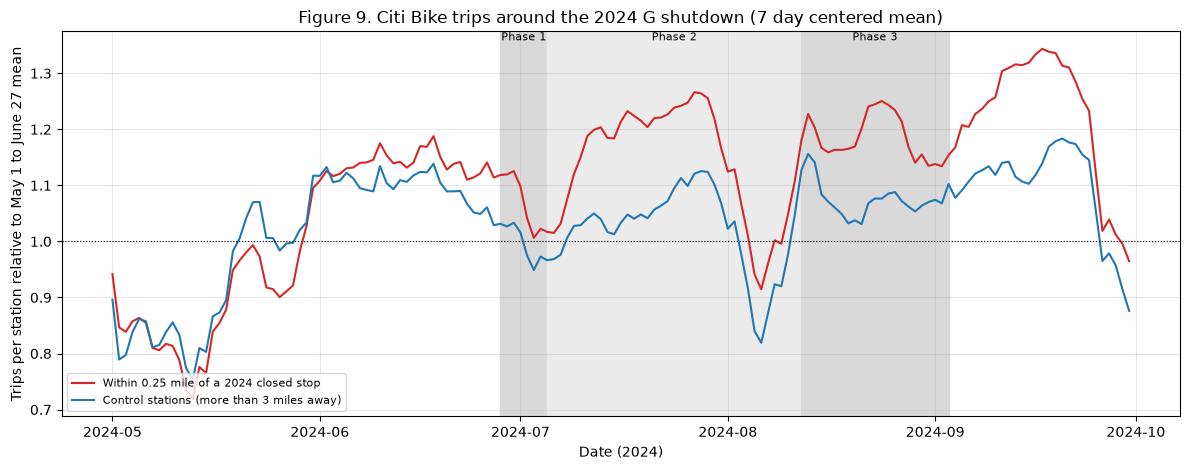

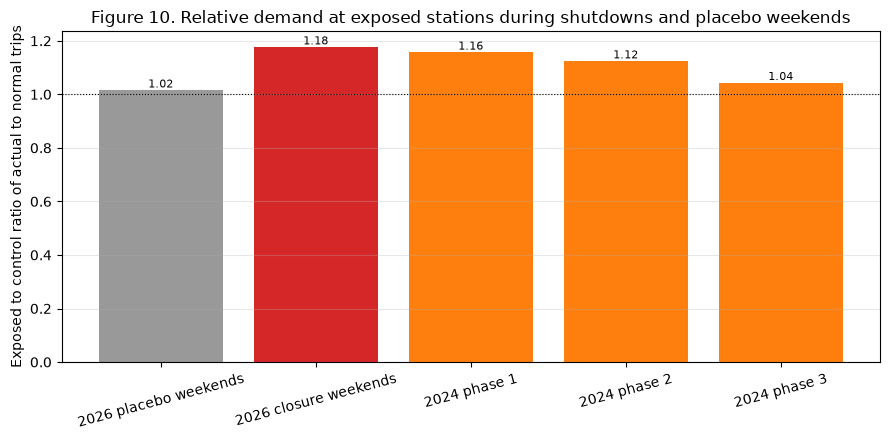

group,Control stations,Exposed stations,exposed_to_control
event,,,
2026 placebo weekends,0.976,0.991,1.016
2026 closure weekends,1.103,1.298,1.177
2024 phase 1,1.006,1.164,1.157
2024 phase 2,1.008,1.133,1.124
2024 phase 3,1.060,1.106,1.044


In [ ]:
import matplotlib.pyplot as plt

# Figure 9: 2024 shutdown check. Daily trips per station relative to the pre shutdown mean, exposed versus control.
p24 = panel_extended[panel_extended["period"].eq("2024") & panel_extended["station_active"]].copy()
p24["group"] = np.where(p24["exposed_station_2024"], "Within 0.25 mile of a 2024 closed stop",
                        np.where(p24["station_group"].eq("control"), "Control stations (more than 3 miles away)", "Other corridor stations"))
p24 = p24[~p24["group"].eq("Other corridor stations")]
daily = p24.groupby(["group", p24["hour"].dt.normalize()])["total_trips"].sum().rename("trips").reset_index()
stations_per_group = p24.groupby("group")["short_name"].nunique()
daily["per_station"] = daily["trips"] / daily["group"].map(stations_per_group)
pre_mean = daily[daily["hour"] < "2024-06-28"].groupby("group")["per_station"].mean()
daily["index"] = daily["per_station"] / daily["group"].map(pre_mean)
daily["smooth"] = daily.groupby("group")["index"].transform(lambda values: values.rolling(7, center=True, min_periods=4).mean())
fig, axis = plt.subplots(figsize=(12, 4.8))
for label, color in (("Within 0.25 mile of a 2024 closed stop", "tab:red"), ("Control stations (more than 3 miles away)", "tab:blue")):
    part = daily[daily["group"].eq(label)]
    axis.plot(part["hour"], part["smooth"], color=color, label=label)
for label, start, end, shade in (("Phase 1", "2024-06-28", "2024-07-05", "0.85"), ("Phase 2", "2024-07-05", "2024-08-12", "0.92"), ("Phase 3", "2024-08-12", "2024-09-03", "0.85")):
    axis.axvspan(pd.Timestamp(start), pd.Timestamp(end), color=shade, zorder=0)
    axis.text(pd.Timestamp(start) + (pd.Timestamp(end) - pd.Timestamp(start)) / 2, axis.get_ylim()[1], label, ha="center", va="top", fontsize=8)
axis.axhline(1, color="black", linewidth=0.8, linestyle=":")
axis.set_xlabel("Date (2024)")
axis.set_ylabel("Trips per station relative to May 1 to June 27 mean")
axis.set_title("Figure 9. Citi Bike trips around the 2024 G shutdown (7 day centered mean)")
axis.legend(fontsize=8, loc="lower left")
axis.grid(alpha=0.3)
fig.tight_layout()
plt.show()

# Figure 10: actual to normal profile ratio at exposed versus control stations, by event type
# Actual to profile demand at exposed and control stations per event type (tf.shutdown_effect_screening; the
# citibike-prepare job saves the same table as shutdown_effect_screening)
event_effect_table = read_table("shutdown_effect_screening")
wide = event_effect_table.pivot(index="event", columns="group", values="actual_to_profile")
wide["exposed_to_control"] = wide["Exposed stations"] / wide["Control stations"]
order = ["2026 placebo weekends", "2026 closure weekends", "2024 phase 1", "2024 phase 2", "2024 phase 3"]
wide = wide.loc[order]
fig, axis = plt.subplots(figsize=(9, 4.5))
bars = axis.bar(wide.index, wide["exposed_to_control"], color=["0.6", "tab:red", "tab:orange", "tab:orange", "tab:orange"])
axis.axhline(1, color="black", linewidth=0.8, linestyle=":")
axis.bar_label(bars, fmt="%.2f", fontsize=8)
axis.set_ylabel("Exposed to control ratio of actual to normal trips")
axis.set_title("Figure 10. Relative demand at exposed stations during shutdowns and placebo weekends")
axis.tick_params(axis="x", labelrotation=15)
axis.grid(alpha=0.3, axis="y")
fig.tight_layout()
plt.show()
display(wide.round(3))

**Figure 9 and Figure 10 explanation.** Figure 9 shows trips per station relative to the May 1 to June 27, 2024 mean, as a seven day centered average, for stations within 0.25 mile of a closed 2024 stop and for control stations. Both lines rise into summer, which is seasonal growth and not a shutdown effect. The line for exposed stations sits above the control line through the three shutdown phases (the shaded bands), which means demand near the closed stops grew faster than demand elsewhere.

Figure 10 turns that comparison into one number per event type: the ratio of actual trips to the normal profile at exposed stations divided by the same ratio at control stations. A value of 1 means no relative change. Placebo weekends give 1.01, so the method finds no effect when nothing happened. Confirmed 2026 closure weekends give 1.17. The three 2024 phases give 1.16, 1.12 and 1.04. The 2024 phase 2 value of about 12 percent is close to the nearly 14 percent increase reported in the proposal. These values are descriptive screening results: they support the main hypothesis that demand rises near closed stops, but they do not control for weather, hour of day or station size. The models in Section 4 will do that. Phase 1 and phase 3 have few exposed station hours (2,923 and 6,206), so they are less certain than phase 2 (39,547).

## Next: analysis

The tables checked in this notebook are the inputs of [02_citibike_demand_analysis.ipynb](02_citibike_demand_analysis.ipynb), which covers the research question (Section 1), exploration and feature engineering (Section 3), model development (Section 4), evaluation (Section 5) and the remaining sections. It starts from `analysis_station_hour_panel_extended` and `analysis_station_hour_panel`.